In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
df=pd.read_csv('creditcard.csv')

In [ ]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0.0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0.0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0.0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0.0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0.0


In [ ]:
df.shape

(7973, 31)

In [ ]:
df.dtypes

,0
Time,int64
V1,float64
V2,float64
V3,float64
V4,float64
V5,float64
V6,float64
V7,float64
V8,float64
V9,float64


In [ ]:
df.isnull().sum()

,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


In [ ]:
df.dropna(inplace=True)

In [ ]:
df.isnull().sum()

,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


In [ ]:
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data:", X_train_scaled.shape)
print("Testing data:", X_test_scaled.shape)

Training data: (6377, 30)
Testing data: (1595, 30)


In [ ]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0.0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0.0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0.0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0.0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0.0


In [ ]:
print("Mean:", X_train_scaled.mean())
print("Standard deviation:", X_train_scaled.std())

Mean: -8.913818231269878e-19
Standard deviation: 1.0


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow import keras

In [ ]:
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:

model =keras. Sequential([
    Input(shape=(X_train_scaled.shape[1],)),

    Dense(64, activation='relu'),
    Dropout(0.3),

    Dense(32, activation='relu'),
    Dropout(0.2),

    Dense(16, activation='relu'),


    Dense(8, activation='relu'),

    Dense(1, activation='sigmoid')
])

In [ ]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy'])

In [ ]:
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=20,
    batch_size=256,
    verbose=1
)

Epoch 1/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.2531 - loss: 0.9371
Epoch 2/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9305 - loss: 0.5426 
Epoch 3/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9967 - loss: 0.3093 
Epoch 4/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9969 - loss: 0.1071 
Epoch 5/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9969 - loss: 0.0442 
Epoch 6/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9969 - loss: 0.0285 
Epoch 7/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9969 - loss: 0.0197 
Epoch 8/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9969 - loss: 0.0147 
Epoch 9/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9970 - loss: 0.0116 
Epoch 10/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9972 - loss: 0.0086 
Epoch 11/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9981 - loss: 0.0071 
Epoch 12/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0

In [ ]:
results = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

for name, value in zip(model.metrics_names, results):
    print(f"{name}: {value:.4f}")

loss: 0.0104
compile_metrics: 0.9994


In [ ]:
import numpy as np

# Fraud probability
y_prob = model.predict(
    X_test_scaled,
    verbose=0
).ravel()

# Default threshold: 0.5
y_pred = (y_prob >= 0.5).astype(int)

print("First 10 fraud probabilities:")
print(y_prob[:10])

print("\nFirst 10 predictions:")
print(y_pred[:10])

First 10 fraud probabilities:
[1.3591838e-04 8.4059102e-06 2.5051020e-07 2.1294926e-04 7.4047210e-05
 2.8167897e-05 4.4098639e-04 3.4437278e-05 1.7404290e-04 7.4564246e-05]

First 10 predictions:
[0 0 0 0 0 0 0 0 0 0]


              precision    recall  f1-score   support

      Normal     0.9994    1.0000    0.9997      1590
       Fraud     1.0000    0.8000    0.8889         5

    accuracy                         0.9994      1595
   macro avg     0.9997    0.9000    0.9443      1595
weighted avg     0.9994    0.9994    0.9993      1595

PR-AUC / Average Precision: 0.8006459948320414


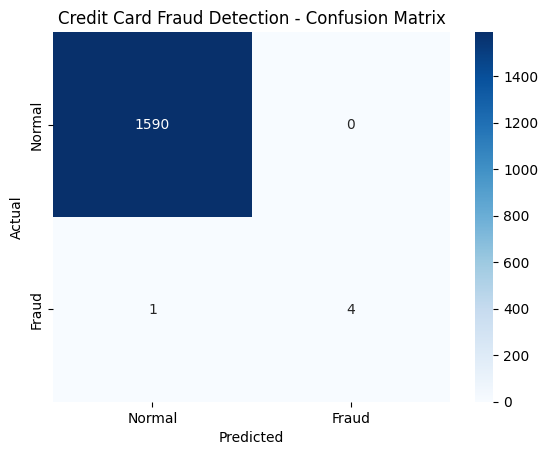

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score
)
import matplotlib.pyplot as plt
import seaborn as sns

print(classification_report(
    y_test,
    y_pred,
    target_names=['Normal', 'Fraud'],
    digits=4,
    zero_division=0
))

print("PR-AUC / Average Precision:",
      average_precision_score(y_test, y_prob))

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Fraud'],
    yticklabels=['Normal', 'Fraud']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Credit Card Fraud Detection - Confusion Matrix')
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score

# Test data par prediction
y_prob = model.predict(X_test_scaled, verbose=0)

y_pred = (y_prob >= 0.5).astype(int).ravel()

# Accuracy calculate karo
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")

Model Accuracy: 99.94%


In [ ]:
model.save("credit_card_fraud_ann.keras")
print("ANN model saved successfully!")

ANN model saved successfully!


In [ ]:
import joblib

joblib.dump(scaler, "credit_card_scaler.pkl")
print("Scaler saved successfully!")

Scaler saved successfully!


In [ ]:
import os

print("Model file exists:",
      os.path.exists("credit_card_fraud_ann.keras"))

print("Scaler file exists:",
      os.path.exists("credit_card_scaler.pkl"))

print("\nFiles in current folder:")
print(os.listdir("/content"))

Model file exists: True
Scaler file exists: True

Files in current folder:
['.config', 'credit_card_fraud_ann.keras', 'credit_card_scaler.pkl', 'creditcard.csv', 'sample_data']


In [ ]:
from google.colab import files

files.download("credit_card_fraud_ann.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download("credit_card_scaler.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>